# p01-five-bridges — Set con rugosidad fija por puente

Datos para entrenar una CNN de monitoreo indirecto (drive-by): a partir de la señal del teléfono dentro del carro y del perfil de la carretera antes y después del puente, estimar el perfil de la carretera y del puente bajo la rueda en cada instante.

**Un perfil de rugosidad fijo por puente.** Todos los viajes sobre un mismo puente pisan exactamente la misma carretera (antes, sobre y después del puente). $G_d(n_0)$ se sortea una vez por puente, dentro de su clase.

**Contenido**

1. [Archivos del set](#1.-Archivos-del-set)
2. [Esquema del viaje](#2.-Esquema-del-viaje)
3. [Modelo](#3.-Modelo)
4. [Puentes](#4.-Puentes)
5. [Lo que cambia entre viajes](#5.-Lo-que-cambia-entre-viajes)
6. [Ejemplo de un viaje](#6.-Ejemplo-de-un-viaje)
7. [Rugosidad del set](#7.-Rugosidad-del-set)
8. [Amplitudes](#8.-Amplitudes)
9. [Versiones 100 m / 200 m y padded / ragged](#9.-Versiones-100-m-/-200-m-y-padded-/-ragged)
10. [Consideraciones y limitaciones](#10.-Consideraciones-y-limitaciones)

Plan completo y decisiones: [`../README.md`](../README.md). Configuración: [`main.yaml`](main.yaml), [`generalization.yaml`](generalization.yaml), [`../p01_base.yaml`](../p01_base.yaml).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import vehicle_bridge_signal as vbs
from vehicle_bridge_signal.roughness import class_bounds, displacement_psd, estimate_gd_n0

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
DATA = Path("data")
SET = "fixed"
main = vbs.load_dataset(DATA / "main_200m_ragged.h5")
gen = vbs.load_dataset(DATA / "generalization_200m_ragged.h5")
meta, gmeta = main.metadata, gen.metadata
SEG_COLORS = {0: "#dbe9f6", 1: "#fde2c8", 2: "#dbe9f6"}


def shade_segments(ax, x, seg):
    """Shade the part of the axis where the wheel is on the bridge."""
    on = np.flatnonzero(seg == 1)
    ax.axvspan(x[on[0]], x[on[-1]], color=SEG_COLORS[1], zorder=0)

## 1. Archivos del set

Se simula una sola vez cada viaje con 200 m de carretera antes y después del puente (`*_200m_ragged.h5`). Los otros archivos se derivan de él sin volver a simular (`vbsig derive`), así que **los cuatro archivos de un paquete tienen exactamente los mismos viajes**.

- `200m` / `100m`: carretera antes y después del puente.
- `ragged`: cada viaje con su propio largo. `padded`: todos con el mismo largo, ceros al final y `valid_mask`.
- `main`: 5 puentes × 200 viajes. `generalization`: 5 puentes no vistos × 50 viajes.

**Tabla 1.** Archivos del set.

In [2]:
rows = []
for f in sorted(DATA.glob("*.h5")):
    with vbs.load_dataset(f) as ds:
        lengths = ds.lengths
        rows.append({"archivo": f.name, "viajes": len(ds), "formato": ds.layout,
                     "muestras por viaje (min-max)": f"{lengths.min()}-{lengths.max()}",
                     "duración (min-max) [s]": f"{lengths.min() / ds.fs:.1f}-{lengths.max() / ds.fs:.1f}",
                     "arreglo measured": str(ds.measured.shape), "tamaño [MB]": round(f.stat().st_size / 2**20)})
pd.DataFrame(rows)

,archivo,viajes,formato,muestras por viaje (min-max),duración (min-max) [s],arreglo measured,tamaño [MB]
0,generalization_100m_padded.h5,250,padded,1756-10649,8.8-53.2,"(250, 11000)",33
1,generalization_100m_ragged.h5,250,ragged,1756-10649,8.8-53.2,"(1023894,)",31
2,generalization_200m_padded.h5,250,padded,3374-18597,16.9-93.0,"(250, 19000)",57
3,generalization_200m_ragged.h5,250,ragged,3374-18597,16.9-93.0,"(1888588,)",54
4,main_100m_padded.h5,1000,padded,1721-10338,8.6-51.7,"(1000, 11000)",130
5,main_100m_ragged.h5,1000,ragged,1721-10338,8.6-51.7,"(4001041,)",122
6,main_200m_padded.h5,1000,padded,3323-18290,16.6-91.5,"(1000, 19000)",224
7,main_200m_ragged.h5,1000,ragged,3323-18290,16.6-91.5,"(7392905,)",214


## 2. Esquema del viaje

El carro recorre a velocidad constante $v$ tres tramos: carretera antes del puente ($L_a$ = 200 o 100 m), el puente (vano $L$) y carretera después ($L_e = L_a$). La posición de la rueda es

$$x(t) = v\,t - L_a \tag{1}$$

con $x = 0$ al inicio del puente. El código `segment` marca el tramo: 0 antes, 1 sobre el puente, 2 después.

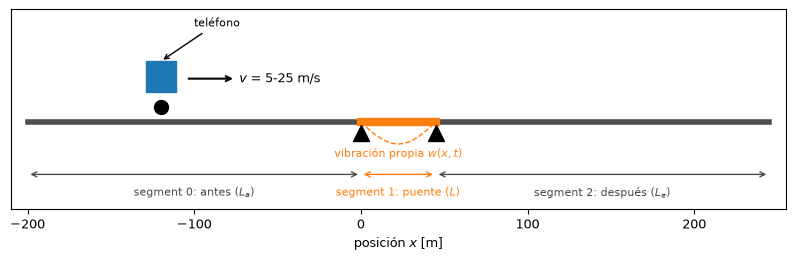

In [3]:
fig, ax = plt.subplots(figsize=(10, 2.6))
La, L = 200.0, 45.0
ax.plot([-La, 0], [0, 0], color="0.3", lw=4)
ax.plot([L, L + La], [0, 0], color="0.3", lw=4)
ax.plot([0, L], [0, 0], color="tab:orange", lw=6)
xs = np.linspace(0, L, 100)
ax.plot(xs, -0.25 * np.sin(np.pi * xs / L), color="tab:orange", lw=1, ls="--")
for xp in (0, L):
    ax.plot([xp], [-0.12], marker="^", ms=12, color="k")
car = -120
ax.add_patch(plt.Rectangle((car - 9, 0.35), 18, 0.35, color="tab:blue"))
ax.plot([car], [0.17], "o", ms=10, color="k")
ax.annotate("teléfono", (car, 0.7), (car + 20, 1.1), arrowprops=dict(arrowstyle="->"), fontsize=8)
ax.annotate("", (car + 45, 0.5), (car + 15, 0.5), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(car + 47, 0.45, "$v$ = 5-25 m/s", fontsize=9)
for x0, x1, lab, c in ((-La, 0, "segment 0: antes ($L_a$)", "0.3"), (0, L, "segment 1: puente ($L$)", "tab:orange"),
                       (L, L + La, "segment 2: después ($L_e$)", "0.3")):
    ax.annotate("", (x0, -0.6), (x1, -0.6), arrowprops=dict(arrowstyle="<->", color=c))
    ax.text((x0 + x1) / 2, -0.85, lab, ha="center", fontsize=8, color=c)
ax.text(L / 2, -0.4, "vibración propia $w(x,t)$", ha="center", fontsize=8, color="tab:orange")
ax.set_xlim(-La - 10, L + La + 10)
ax.set_ylim(-1.0, 1.3)
ax.set_xlabel("posición $x$ [m]")
ax.set_yticks([])
ax.grid(False)
plt.show()

**Figura 1.** Esquema del viaje (vano de ejemplo L = 45 m). El puente vibra por sí mismo (vibración ambiental); el carro no lo carga, solo recorre su superficie.

## 3. Modelo

Solo cuatro fuentes de vibración: **puente, rugosidad, vehículo y ruido del teléfono**. Sin motor, soporte del teléfono ni excentricidad de rueda. Interacción desacoplada y amplitudes reales.

**Puente** (viga simplemente apoyada, superposición modal):

$$w(x,t) = \sum_{n=1}^{N} \phi_n(x)\,q_n(t), \qquad \phi_n(x) = \sin\frac{n\pi x}{L}, \qquad f_n = n^2 f_1 \tag{2}$$

- $w$: desplazamiento vertical [m]; $q_n$: amplitud del modo $n$; $N$: modos con $f_n \le 40$ Hz.
- Cada $q_n$ responde a una fuerza modal de ruido blanco (vibración ambiental) y empieza en su estado estacionario, así que el puente ya vibra cuando llega el carro. Nivel: $a_{\mathrm{rms}} = \omega_n^2\,\sigma_{q_n}$, log-uniforme entre 0.001 y 0.01 m/s² en cada viaje.
- El peso del carro **no** carga al puente (`vehicle_loads_bridge: false`).

**Vehículo** (cuarto de carro: carrocería $m_s$ sobre suspensión $k_s, c_s$; rueda $m_u$ sobre llanta $k_t$):

$$m_s\ddot z_s + c_s(\dot z_s-\dot z_u) + k_s(z_s-z_u) = 0, \qquad m_u\ddot z_u - c_s(\dot z_s-\dot z_u) - k_s(z_s-z_u) + k_t(z_u-u) = 0 \tag{3}$$

- $u(t) = r(x(t)) + w(x(t),t)$: lo que pisa la rueda (rugosidad + puente).
- Un carro nuevo en cada viaje: $m_s$ 250–500 kg, $m_u$ 30–100 kg, rebote 1–2 Hz, salto de rueda 8–15 Hz, $\zeta_s$ 0.2–0.4.

**Rugosidad** (ISO 8608, suma de armónicos con fases aleatorias):

$$G_d(n) = G_d(n_0)\left(\frac{n}{n_0}\right)^{-2}, \qquad r(x) = \sum_i \sqrt{2G_d(n_i)\Delta n}\,\cos(2\pi n_i x + \varphi_i) \tag{4}$$

- $n$: frecuencia espacial [ciclos/m], $n_0 = 0.1$, banda 0.01–10 ciclos/m, suavizado de 0.25 m (huella de la llanta).
- En este set: `roughness.scope: bridge`.

**Teléfono** (aceleración vertical de la carrocería):

$$y(t_k) = \mathcal{D}\Big\{H_{aa} * \big[\ddot z_s + \varepsilon\big]\Big\}, \qquad \sigma_\varepsilon = ND\cdot g\sqrt{f_{s,\mathrm{sim}}/2} \tag{5}$$

- $\varepsilon$: ruido blanco con densidad $ND$ uniforme 100–400 µg/√Hz en cada viaje; $H_{aa}$: anti-alias Butterworth de orden 4 (80 Hz); $\mathcal{D}$: diezmado de 1000 a 200 Hz.

**Salidas** (exactas, sin filtro, en cada medición $t_k$):

$$r\big(x(t_k)\big), \quad v^2 r''\big(x(t_k)\big), \quad w\big(x(t_k),t_k\big) = \sum_n \phi_n\big(x(t_k)\big)q_n(t_k), \quad \ddot w = \sum_n \phi_n\big(x(t_k)\big)\ddot q_n(t_k) \tag{6}$$

- Desplazamiento y aceleración de la carretera bajo la rueda; desplazamiento y aceleración del punto del puente bajo la rueda (cero fuera del puente).

## 4. Puentes

**Tabla 2.** Puentes del paquete principal (B) y del de generalización (G). Frecuencias de los modos retenidos ($f_n \le$ 40 Hz) y $G_d(n_0)$ de la rugosidad (en este set).

In [4]:
def bridge_table(m):
    rows = []
    for name in sorted(set(m["bridge_name"])):
        i = np.flatnonzero(m["bridge_name"] == name)
        f = m["bridge_frequencies"][i[0]]
        gd = m["roughness_gd_n0"][i] * 1e6
        rows.append({"puente": name, "L [m]": m["span"][i[0]], "f1 [Hz]": m["f1"][i[0]],
                     "masa [kg/m]": m["mass_per_length"][i[0]], "zeta [%]": 100 * m["bridge_damping_ratios"][i[0], 0],
                     "clase": m["roughness_class"][i[0]], "modos": int(m["n_modes"][i[0]]),
                     "f_n [Hz]": ", ".join(f"{x:.1f}" for x in f[np.isfinite(f)]),
                     "Gd(n0) [1e-6 m^3]": f"{gd.min():.0f}" if np.ptp(gd) == 0 else f"{gd.min():.0f}-{gd.max():.0f}",
                     "viajes": i.size})
    return pd.DataFrame(rows)

pd.concat([bridge_table(meta), bridge_table(gmeta)], ignore_index=True)

,puente,L [m],f1 [Hz],masa [kg/m],zeta [%],clase,modos,f_n [Hz],Gd(n0) [1e-6 m^3],viajes
0,B1,15.0,8.0,5000.0,2.0,A,2,"8.0, 32.0",11,200
1,B2,25.0,4.5,8000.0,1.5,B,2,"4.5, 18.0",80,200
2,B3,35.0,3.0,12000.0,1.2,C,3,"3.0, 12.0, 27.0",491,200
3,B4,45.0,2.3,15000.0,1.0,B,4,"2.3, 9.2, 20.7, 36.8",60,200
4,B5,60.0,1.6,20000.0,0.8,A,5,"1.6, 6.4, 14.4, 25.6, 40.0",13,200
5,G1,17.0,7.0,5800.0,2.0,A,2,"7.0, 28.0",13,50
6,G2,21.5,5.2,7000.0,1.5,B,2,"5.2, 20.8",64,50
7,G3,40.0,2.6,13800.0,1.2,C,3,"2.6, 10.4, 23.4",320,50
8,G4,39.0,2.7,13000.0,1.0,B,3,"2.7, 10.8, 24.3",82,50
9,G5,68.0,1.4,17000.0,0.8,A,5,"1.4, 5.6, 12.6, 22.4, 35.0",15,50


## 5. Lo que cambia entre viajes

Velocidad, vehículo, vibración previa del puente y nivel de ruido se sortean en cada viaje (paquete principal en la figura).

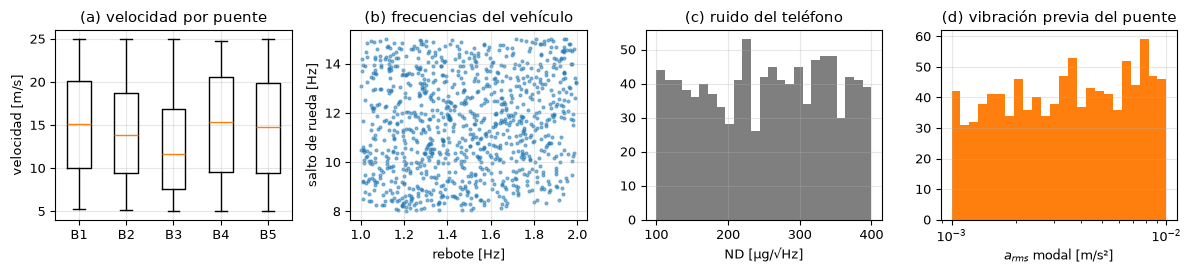

In [5]:
fig, axs = plt.subplots(1, 4, figsize=(12, 2.8))
names = sorted(set(meta["bridge_name"]))
axs[0].boxplot([meta["speed"][meta["bridge_name"] == b] for b in names], tick_labels=names)
axs[0].set(ylabel="velocidad [m/s]", title="(a) velocidad por puente")
vf = meta["vehicle_frequencies"]
axs[1].scatter(vf[:, 0], vf[:, 1], s=4, alpha=0.5)
axs[1].set(xlabel="rebote [Hz]", ylabel="salto de rueda [Hz]", title="(b) frecuencias del vehículo")
axs[2].hist(meta["noise_density_ug"], bins=25, color="tab:gray")
axs[2].set(xlabel="ND [µg/√Hz]", title="(c) ruido del teléfono")
axs[3].hist(meta["param.ambient.modal_accel_rms"], bins=np.logspace(-3, -2, 25), color="tab:orange")
axs[3].set(xscale="log", xlabel="$a_{rms}$ modal [m/s²]", title="(d) vibración previa del puente")
plt.tight_layout()
plt.show()

**Figura 2.** Parámetros sorteados por viaje (paquete principal, 1000 viajes).

Los viajes con despegue de rueda se descartaron y se volvieron a sortear (vehículo, velocidad, vibración y ruido). Como el despegue ocurre sobre todo a alta velocidad en carretera más rugosa, en esos puentes quedan menos viajes rápidos.

**Tabla 3.** Viajes vueltos a sortear por despegue de rueda.

In [6]:
def lift_table(m):
    rows = []
    for b in sorted(set(m["bridge_name"])):
        s = m["bridge_name"] == b
        rows.append({"puente": b, "clase": m["roughness_class"][s][0], "viajes": int(s.sum()),
                     "vueltos a sortear": int((m["lift_off_resamples"][s] > 0).sum()),
                     "sorteos descartados": int(m["lift_off_resamples"][s].sum()),
                     "velocidad media [m/s]": round(float(m["speed"][s].mean()), 1)})
    return pd.DataFrame(rows)

pd.concat([lift_table(meta), lift_table(gmeta)], ignore_index=True)

,puente,clase,viajes,vueltos a sortear,sorteos descartados,velocidad media [m/s]
0,B1,A,200,0,0,15.1
1,B2,B,200,21,21,14.3
2,B3,C,200,106,220,12.6
3,B4,B,200,13,15,15.3
4,B5,A,200,0,0,14.8
5,G1,A,50,0,0,15.7
6,G2,B,50,5,6,14.3
7,G3,C,50,20,25,13.5
8,G4,B,50,9,10,13.3
9,G5,A,50,0,0,14.9


## 6. Ejemplo de un viaje

Entrada de la CNN: `measured` y el perfil de la carretera en los segmentos 0 y 2. Salidas: las cuatro magnitudes de la Ec. 6 en todo el viaje.

viaje 46: puente B4, v = 15.0 m/s, 5918 muestras (29.6 s), vehículo 1.87 / 10.8 Hz, ND = 245 µg/√Hz


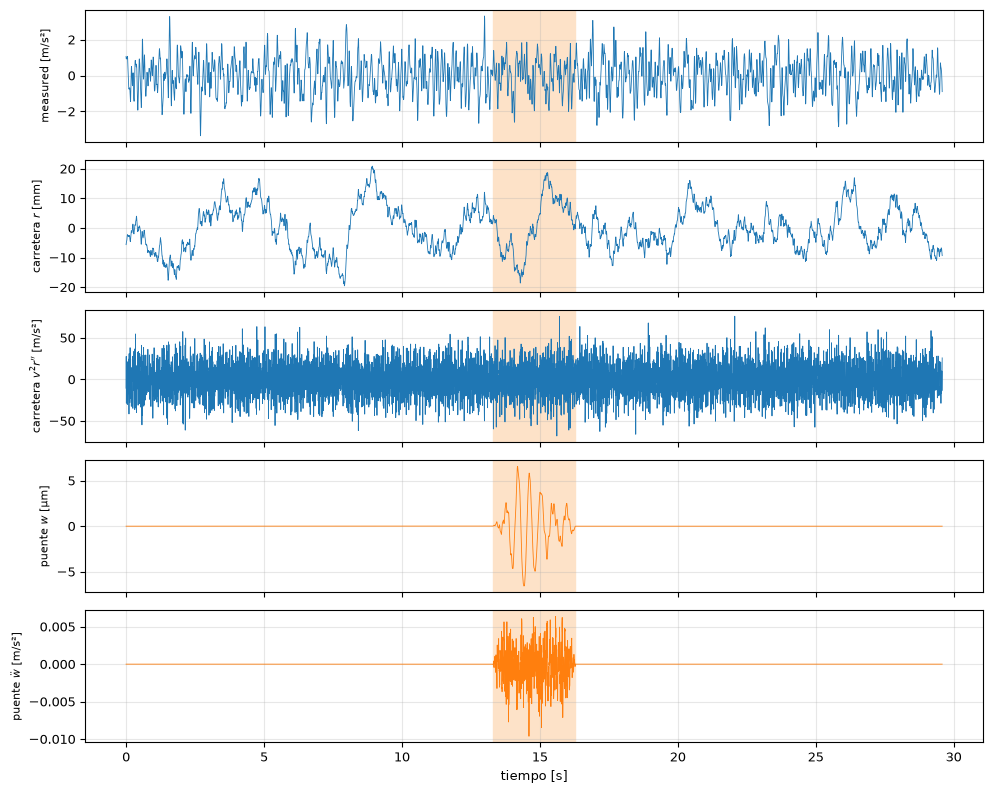

In [7]:
i = int(np.flatnonzero((meta["bridge_name"] == "B4") & (meta["speed"] > 12) & (meta["speed"] < 16))[0])
smp = main.sample(i)
t, seg, p = smp["time"], smp["segment"], smp["profile"]
m = smp["metadata"]
print(f"viaje {i}: puente {m['bridge_name']}, v = {m['speed']:.1f} m/s, {t.size} muestras ({t[-1]:.1f} s), "
      f"vehículo {m['vehicle_frequencies'][0]:.2f} / {m['vehicle_frequencies'][1]:.1f} Hz, ND = {m['noise_density_ug']:.0f} µg/√Hz")
rows = [("measured [m/s²]", smp["measured"]), ("carretera $r$ [mm]", 1e3 * p["road_displacement"][0]),
        ("carretera $v^2r''$ [m/s²]", p["road_acceleration"][0]), ("puente $w$ [µm]", 1e6 * p["bridge_displacement"][0]),
        ("puente $\\ddot w$ [m/s²]", p["bridge_acceleration"][0])]
fig, axs = plt.subplots(len(rows), 1, figsize=(10, 8), sharex=True)
for ax, (lab, y) in zip(axs, rows):
    shade_segments(ax, t, seg)
    ax.plot(t, y, lw=0.6, color="tab:orange" if "puente" in lab else "tab:blue")
    ax.set_ylabel(lab, fontsize=8)
axs[-1].set_xlabel("tiempo [s]")
plt.tight_layout()
plt.show()

**Figura 3.** Un viaje del puente B4 en función del tiempo. Fondo naranja: rueda sobre el puente. La señal del teléfono está dominada por la rugosidad; el puente (filas 4 y 5) es miles de veces más pequeño que la carretera (fila 2).

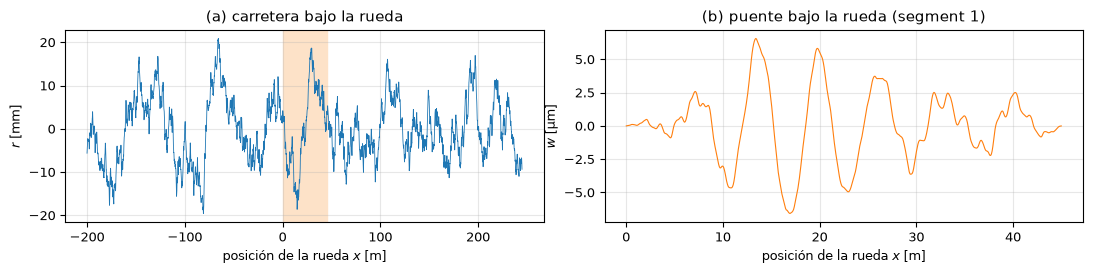

In [8]:
x = p["position"][0]
fig, axs = plt.subplots(1, 2, figsize=(11, 2.8))
shade_segments(axs[0], x, seg)
axs[0].plot(x, 1e3 * p["road_displacement"][0], lw=0.6)
axs[0].set(xlabel="posición de la rueda $x$ [m]", ylabel="$r$ [mm]", title="(a) carretera bajo la rueda")
on = seg == 1
axs[1].plot(x[on], 1e6 * p["bridge_displacement"][0][on], color="tab:orange", lw=0.8)
axs[1].set(xlabel="posición de la rueda $x$ [m]", ylabel="$w$ [µm]", title="(b) puente bajo la rueda (segment 1)")
plt.tight_layout()
plt.show()

**Figura 4.** El mismo viaje en función de la posición de la rueda (`profile/position`): cada punto es una medición.

## 7. Rugosidad del set

**Un perfil de rugosidad fijo por puente.** Todos los viajes sobre un mismo puente pisan exactamente la misma carretera (antes, sobre y después del puente). $G_d(n_0)$ se sortea una vez por puente, dentro de su clase.

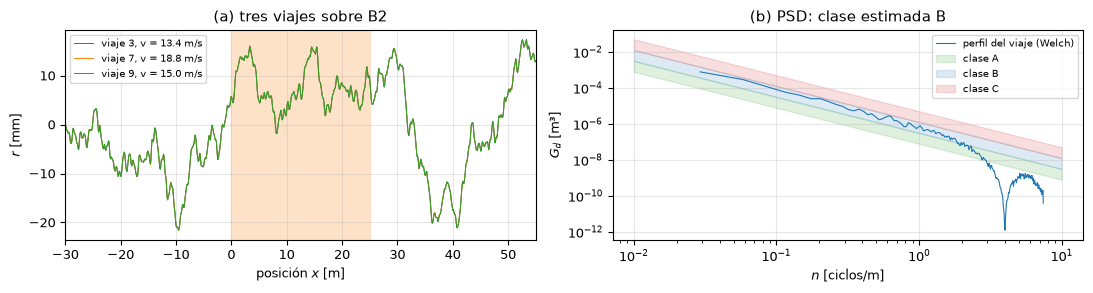

In [9]:
idx = np.flatnonzero(meta["bridge_name"] == "B2")[:3]
fig, axs = plt.subplots(1, 2, figsize=(11, 3))
for j in idx:
    pj = main.signal("profile/position", j)[0], main.signal("profile/road_displacement", j)[0]
    axs[0].plot(pj[0], 1e3 * pj[1], lw=0.7, label=f"viaje {j}, v = {meta['speed'][j]:.1f} m/s")
axs[0].axvspan(0, meta["span"][idx[0]], color=SEG_COLORS[1], zorder=0)
axs[0].set(xlim=(-30, 55), xlabel="posición $x$ [m]", ylabel="$r$ [mm]", title="(a) tres viajes sobre B2")
axs[0].legend(fontsize=7)
j = idx[0]
xj, rj = main.signal("profile/position", j)[0], main.signal("profile/road_displacement", j)[0]
est = estimate_gd_n0(rj.astype(float), float(np.diff(xj).mean()), band=(0.05, 1.0))   # below the tyre smoothing
axs[1].loglog(est["n"][1:], est["psd"][1:], lw=0.8, label="perfil del viaje (Welch)")
n = np.logspace(-2, 1, 50)
for c, col in (("A", "tab:green"), ("B", "tab:blue"), ("C", "tab:red")):
    lo, hi = class_bounds(c)
    axs[1].fill_between(n, displacement_psd(n, lo), displacement_psd(n, hi), alpha=0.15, color=col, label=f"clase {c}")
axs[1].set(xlabel="$n$ [ciclos/m]", ylabel="$G_d$ [m³]", title=f"(b) PSD: clase estimada {est['class']}")
axs[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

**Figura 5.** (a) Perfil bajo la rueda en tres viajes del puente B2 (clase B): los tres perfiles coinciden: es la misma carretera, recorrida a distinta velocidad. (b) Densidad espectral del perfil de un viaje frente a las bandas ISO 8608; la caída sobre 2 ciclos/m es el suavizado de 0.25 m (por eso la clase se estima entre 0.05 y 1 ciclos/m).

## 8. Amplitudes

Amplitudes reales (sin amplificar el puente). Cada archivo guarda la descomposición exacta de `measured` por fuente (`components/*`), lo que permite medir cuánto aporta cada una mientras la rueda está sobre el puente.

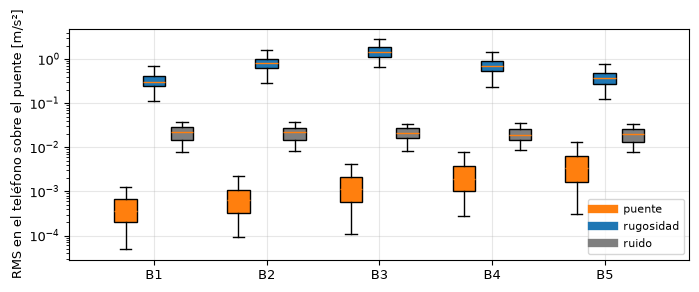

mediana puente/rugosidad: -56 dB; puente/ruido: -25 dB


In [10]:
fig, ax = plt.subplots(figsize=(8, 3))
pos = np.arange(len(names))
for k, (key, lab, col) in enumerate((("rms_bridge_on", "puente", "tab:orange"), ("rms_roughness_on", "rugosidad", "tab:blue"),
                                    ("rms_noise_on", "ruido", "tab:gray"))):
    data = [meta[key][meta["bridge_name"] == b] for b in names]
    bp = ax.boxplot(data, positions=pos + (k - 1) * 0.25, widths=0.2, patch_artist=True, showfliers=False)
    for box in bp["boxes"]:
        box.set_facecolor(col)
    ax.plot([], [], color=col, lw=6, label=lab)
ax.set(yscale="log", xticks=pos, xticklabels=names, ylabel="RMS en el teléfono sobre el puente [m/s²]")
ax.legend(fontsize=8)
plt.show()
print("mediana puente/rugosidad:", f"{np.median(meta['ratio_db_bridge_to_roughness']):.0f} dB;",
      "puente/ruido:", f"{np.median(meta['ratio_db_bridge_to_noise']):.0f} dB")

**Figura 6.** Aporte de cada fuente a la señal del teléfono mientras la rueda está sobre el puente. El puente queda varios órdenes de magnitud por debajo de la rugosidad y por debajo del ruido: es el caso físico real.

## 9. Versiones 100 m / 200 m y padded / ragged

El archivo de 100 m es un recorte del de 200 m: mismas muestras, mismos valores. La versión `padded` rellena con ceros hasta un largo común (19 000 muestras para 200 m y 11 000 para 100 m) y marca las muestras reales en `valid_mask`.

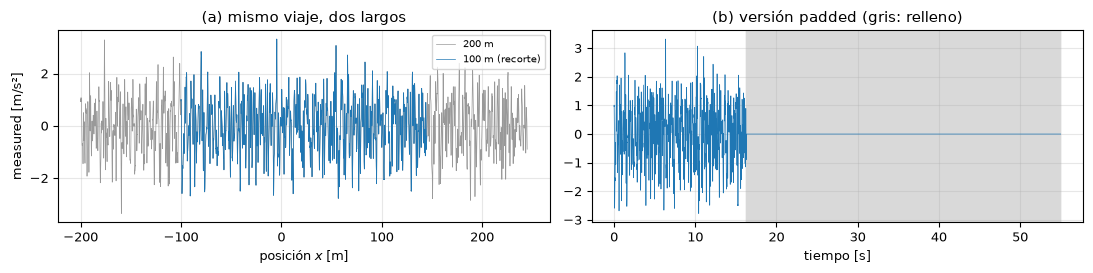

el recorte de 100 m es idéntico al tramo correspondiente de 200 m: True


In [11]:
j = i
with vbs.load_dataset(DATA / "main_100m_padded.h5") as short:
    x200, y200 = main.signal("profile/position", j)[0], main.signal("measured", j)
    y100_pad = short.measured[j]
    valid = short.file["valid_mask"][j].astype(bool)
    x100 = short.signal("profile/position", j)[0]
    j0 = int(short.metadata["crop_start_index"][j])
    same = np.array_equal(short.signal("measured", j), y200[j0:j0 + valid.sum()])
fig, axs = plt.subplots(1, 2, figsize=(11, 2.8))
axs[0].plot(x200, y200, lw=0.5, color="0.6", label="200 m")
axs[0].plot(x100, y100_pad[valid], lw=0.5, color="tab:blue", label="100 m (recorte)")
axs[0].set(xlabel="posición $x$ [m]", ylabel="measured [m/s²]", title="(a) mismo viaje, dos largos")
axs[0].legend(fontsize=7)
axs[1].plot(np.arange(y100_pad.size) / main.fs, y100_pad, lw=0.5)
axs[1].fill_between(np.arange(y100_pad.size) / main.fs, -1, 1, where=~valid, color="0.85", transform=axs[1].get_xaxis_transform())
axs[1].set(xlabel="tiempo [s]", title="(b) versión padded (gris: relleno)")
plt.tight_layout()
plt.show()
print("el recorte de 100 m es idéntico al tramo correspondiente de 200 m:", same)

**Figura 7.** (a) Señal del teléfono de un viaje en los archivos de 200 m y 100 m. (b) El mismo viaje en la versión padded.

Lectura típica para entrenar (versión padded):

In [12]:
with vbs.load_dataset(DATA / "main_100m_padded.h5") as ds:
    X = ds.measured[:]                                   # (viajes, T) señal del teléfono
    valid = ds.file["valid_mask"][:].astype(bool)        # muestras reales
    seg = ds.file["segment"][:]                          # 0 antes, 1 puente, 2 después
    road = ds.file["profile/road_displacement"][:, 0]    # (viajes, T) salida / entrada en seg 0 y 2
    bridge = ds.file["profile/bridge_displacement"][:, 0]
    bridge_id = ds.metadata["bridge_id"]
print(X.shape, valid.shape, road.shape, bridge.shape, np.bincount(bridge_id))
# versión ragged: ds.signal("measured", i) devuelve el viaje i sin relleno

(1000, 11000) (1000, 11000) (1000, 11000) (1000, 11000) [200 200 200 200 200]


## 10. Consideraciones y limitaciones

**Decisiones del paquete**

- Interacción desacoplada; el carro no carga al puente: el puente vibra solo por su vibración previa (ambiental).
- Desplazamiento del puente: solo su oscilación propia. Aceleración del puente: la del punto bajo la rueda.
- Amplitudes físicas; sin división entrenamiento/validación/prueba (se hace al entrenar).
- Semillas: paquete principal 1, generalización 2. Los dos sets usan las mismas semillas, así que comparten vehículo, velocidad, vibración y ruido en los viajes que no se volvieron a sortear.

**Limitaciones**

- El modelo es lineal: la rueda nunca se despega. Por eso los viajes con despegue se descartaron, lo que reduce la proporción de viajes rápidos en los puentes con carretera más rugosa (Tabla 3).
- El nivel de la vibración ambiental (0.001–0.01 m/s²) es un supuesto, no un valor medido.
- La señal del puente en el teléfono es muy pequeña frente a la rugosidad y al ruido (Figura 6); recuperarla es el reto de la CNN.
- Un solo eje (cuarto de carro), velocidad constante y puente simplemente apoyado sin daño.

Regenerar todo: `python ../generate_p01.py` (los `.h5` no se suben a git).